<a href="https://colab.research.google.com/github/aswathyjain70-ctrl/Bike-Sharing-App/blob/main/Miniproject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**STEP 1**

**1. What is your data source?**

Data source is the Bike Sharing Dataset (specifically loaded from /content/hour.csv). This dataset is typically sourced from the UCI Machine Learning Repository and originates from the Capital Bikeshare system in Washington, D.C.

**2. Why did you choose it?**

This dataset is an industry favorite for data engineering and machine learning portfolios because:

Rich feature set: It combines temporal data (hourly timestamps) with
environmental/weather factors, making it perfect for demonstrating end-to-end ETL (Extract, Transform, Load) pipelines.

Clear targets: Having separate columns for casual and registered users allows for interesting multi-target analysis and aggregation.

Manageable size: At 17,379 records, it’s large enough to be meaningful but small enough to process instantly in a Colab environment.

**3. What information does it contain? **

The dataset captures hourly counts of rental bikes along with contextual weather and seasonal information. Specifically, it includes:

Core Identifiers & Time: Record ID, date, season, year, month, hour, and day flags (holiday, weekday, working day).

Weather Metrics: Weather situation (clear, mist, rain/snow), normalized temperature, normalized "feels-like" temperature, humidity, and wind speed.

Rental Counts: A breakdown of casual users, registered users, and the total count (cnt) of rentals.

**4. Is it structured, semi-structured, or unstructured?**

It is structured data. Every record follows a rigid, predefined schema where rows represent specific hourly observations and columns represent clearly defined variables with strict data types

**5. What format is the data?**

The raw file format is a CSV

**6. How frequently is the data updated?**

The specific dataset you are using is a static, historical snapshot covering the years 2011 and 2012. It does not update automatically. However, the underlying system it was built from (Capital Bikeshare) updates its open data feeds monthly.







**STEP 3**

[ Data Source ]  <-- (/content/hour.csv)
              │
              ▼
         [ Extract ]    <-- pd.read_csv(), profiles dataset,
              │             and saves 'hour_raw.csv'
              ▼
     [ Validate & Clean ] <-- Checks for duplicate records
              │
              ▼
       [ Transform ]    <-- Renames 17 columns, converts 'Date' to datetime,
              │             maps numerical codes to strings (Seasons,
              │             Months, Weather, Weekdays, Holidays, Years)
              │
              ▼
    [ Generate Reports ] <-- Groups & aggregates data into:
              │              1. Summary Statistics
              │              2. Top 10 Records & Bottom 10 Records
              │              3. Monthly Rental Report
              │              4. Season-wise Rental Report
              │
              ▼
           [ Load ]     <-- Saves final 'cleaned_bike_data.csv' and
                            exports all generated reports into directories

In [ ]:
import pandas as pd
import numpy as np
import requests
from datetime import datetime
import os

In [ ]:
pd.read_csv('/content/hour.csv')

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0000,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0000,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0000,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0000,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0000,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17374,17375,2012-12-31,1,1,12,19,0,1,1,2,0.26,0.2576,0.60,0.1642,11,108,119
17375,17376,2012-12-31,1,1,12,20,0,1,1,2,0.26,0.2576,0.60,0.1642,8,81,89
17376,17377,2012-12-31,1,1,12,21,0,1,1,1,0.26,0.2576,0.60,0.1642,7,83,90
17377,17378,2012-12-31,1,1,12,22,0,1,1,1,0.26,0.2727,0.56,0.1343,13,48,61


In [ ]:
DATA_PATH = "/content/hour.csv"

RAW_DATA_DIR = "raw_data"
REPORTS_DIR = "reports"
OUTPUT_DIR = "output"

In [ ]:
os.makedirs(RAW_DATA_DIR, exist_ok=True)
os.makedirs(REPORTS_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Folders created successfully.")

Folders created successfully.


In [ ]:
def extract():

    print("="*50)
    print("EXTRACT STAGE")
    print("="*50)

    df = pd.read_csv(DATA_PATH)

    print(f"\nNumber of Records : {df.shape[0]}")
    print(f"Number of Columns : {df.shape[1]}")

    print("\nColumn Names")
    print(df.columns.tolist())

    print("\nData Types")
    print(df.dtypes)

    print("\nMissing Values")
    print(df.isnull().sum())

    raw_path = os.path.join(RAW_DATA_DIR, "hour_raw.csv")
    df.to_csv(raw_path, index=False)

    print("\nRaw dataset saved successfully.")

    return df

In [ ]:
df = extract()

df.head()

EXTRACT STAGE

Number of Records : 17379
Number of Columns : 17

Column Names
['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']

Data Types
instant         int64
dteday         object
season          int64
yr              int64
mnth            int64
hr              int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object

Missing Values
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Raw dataset saved successfully.


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [ ]:
def transform(df):

    print("=" * 50)
    print("TRANSFORM STAGE")
    print("=" * 50)

    # Check duplicate records
    print("\nDuplicate Records :", df.duplicated().sum())

    # Remove duplicate records
    df.drop_duplicates(inplace=True)

    # Rename columns
    df.rename(columns={
        "instant": "Record_ID",
        "dteday": "Date",
        "yr": "Year",
        "mnth": "Month",
        "hr": "Hour",
        "season": "Season",
        "holiday": "Holiday",
        "weekday": "Weekday",
        "workingday": "Working_Day",
        "weathersit": "Weather",
        "temp": "Temperature",
        "atemp": "Feels_Like_Temperature",
        "hum": "Humidity",
        "windspeed": "Wind_Speed",
        "casual": "Casual_Users",
        "registered": "Registered_Users",
        "cnt": "Total_Rentals"
    }, inplace=True)

    # Convert Date to datetime
    df["Date"] = pd.to_datetime(df["Date"])

    # Convert Month values
    df["Month"] = df["Month"].replace(
        [1,2,3,4,5,6,7,8,9,10,11,12],
        ["January","February","March","April","May","June",
         "July","August","September","October","November","December"]
    )

    # Convert Season values
    df["Season"] = df["Season"].replace(
        [1,2,3,4],
        ["Spring","Summer","Fall","Winter"]
    )

    # Convert Weather values
    df["Weather"] = df["Weather"].replace(
        [1,2,3,4],
        ["Clear","Mist","Light Snow/Rain","Heavy Rain/Snow"]
    )

    # Convert Year values
    df["Year"] = df["Year"].replace(
        [0,1],
        ["2011","2012"]
    )

    # Convert Holiday values
    df["Holiday"] = df["Holiday"].replace(
        [0,1],
        ["No","Yes"]
    )

    # Convert Weekday values
    df["Weekday"] = df["Weekday"].replace(
        [0,1,2,3,4,5,6],
        ["Sunday","Monday","Tuesday","Wednesday",
         "Thursday","Friday","Saturday"]
    )

    # Remove unwanted columns
    df.drop(columns=["Working_Day", "Day_Type"], errors="ignore", inplace=True)

    # Sort records
    df.sort_values(by=["Date", "Hour"], inplace=True)

    # Reset index
    df.reset_index(drop=True, inplace=True)

    # Rearrange columns
    df = df[
        [
            "Record_ID",
            "Date",
            "Month",
            "Year",
            "Hour",
            "Season",
            "Holiday",
            "Weekday",
            "Weather",
            "Temperature",
            "Feels_Like_Temperature",
            "Humidity",
            "Wind_Speed",
            "Casual_Users",
            "Registered_Users",
            "Total_Rentals"
        ]
    ]

    print("\nTransformation Completed Successfully.")
    print("\nTransformed Dataset Preview:")
    print(df.head())

    return df

In [ ]:
df = transform(df)
df.tail(15)

TRANSFORM STAGE

Duplicate Records : 0

Transformation Completed Successfully.

Transformed Dataset Preview:
   Record_ID       Date    Month  Year  Hour  Season Holiday   Weekday  \
0          1 2011-01-01  January  2011     0  Spring      No  Saturday   
1          2 2011-01-01  January  2011     1  Spring      No  Saturday   
2          3 2011-01-01  January  2011     2  Spring      No  Saturday   
3          4 2011-01-01  January  2011     3  Spring      No  Saturday   
4          5 2011-01-01  January  2011     4  Spring      No  Saturday   

  Weather  Temperature  Feels_Like_Temperature  Humidity  Wind_Speed  \
0   Clear         0.24                  0.2879      0.81         0.0   
1   Clear         0.22                  0.2727      0.80         0.0   
2   Clear         0.22                  0.2727      0.80         0.0   
3   Clear         0.24                  0.2879      0.75         0.0   
4   Clear         0.24                  0.2879      0.75         0.0   

   Casual_Use

,Record_ID,Date,Month,Year,Hour,Season,Holiday,Weekday,Weather,Temperature,Feels_Like_Temperature,Humidity,Wind_Speed,Casual_Users,Registered_Users,Total_Rentals
17364,17365,2012-12-31,December,2012,9,Spring,No,Monday,Mist,0.18,0.2121,0.64,0.1045,13,144,157
17365,17366,2012-12-31,December,2012,10,Spring,No,Monday,Mist,0.20,0.2121,0.69,0.1343,33,87,120
17366,17367,2012-12-31,December,2012,11,Spring,No,Monday,Mist,0.22,0.2273,0.60,0.1940,43,114,157
17367,17368,2012-12-31,December,2012,12,Spring,No,Monday,Mist,0.24,0.2273,0.56,0.1940,52,172,224
17368,17369,2012-12-31,December,2012,13,Spring,No,Monday,Mist,0.26,0.2576,0.44,0.1642,38,165,203
17369,17370,2012-12-31,December,2012,14,Spring,No,Monday,Mist,0.28,0.2727,0.45,0.2239,62,185,247
17370,17371,2012-12-31,December,2012,15,Spring,No,Monday,Mist,0.28,0.2879,0.45,0.1343,69,246,315
17371,17372,2012-12-31,December,2012,16,Spring,No,Monday,Mist,0.26,0.2576,0.48,0.1940,30,184,214
17372,17373,2012-12-31,December,2012,17,Spring,No,Monday,Mist,0.26,0.2879,0.48,0.0896,14,150,164
17373,17374,2012-12-31,December,2012,18,Spring,No,Monday,Mist,0.26,0.2727,0.48,0.1343,10,112,122


In [ ]:
def load(df):

    print("=" * 50)
    print("LOAD STAGE")
    print("=" * 50)

    # Save Cleaned Dataset
    cleaned_path = os.path.join(OUTPUT_DIR, "cleaned_bike_data.csv")
    df.to_csv(cleaned_path, index=False)
    print(f"Cleaned dataset saved: {cleaned_path}")

    # Report 1 - Summary Statistics
    summary = df.describe(include="all")
    summary.to_csv(os.path.join(REPORTS_DIR, "summary_statistics.csv"))

    # Report 2 - Top 10 Records
    df.head(10).to_csv(
        os.path.join(REPORTS_DIR, "top10_records.csv"),
        index=False
    )

    # Report 3 - Bottom 10 Records
    df.tail(10).to_csv(
        os.path.join(REPORTS_DIR, "bottom10_records.csv"),
        index=False
    )

    # Report 4 - Monthly Rental Report
    monthly_report = df.groupby("Month")["Total_Rentals"].sum().reset_index()
    monthly_report.to_csv(
        os.path.join(REPORTS_DIR, "monthly_rental_report.csv"),
        index=False
    )

    # Report 5 - Season-wise Rental Report
    season_report = df.groupby("Season")["Total_Rentals"].sum().reset_index()
    season_report.to_csv(
        os.path.join(REPORTS_DIR, "season_wise_rental_report.csv"),
        index=False
    )

    print("\nAll reports generated successfully.")
    print("\nLoad Stage Completed Successfully.")

In [ ]:
def run_etl_pipeline():

    df = extract()
    df = transform(df)
    load(df)

    print("\nETL Pipeline Executed Successfully.")

In [ ]:
if __name__ == "__main__":
    run_etl_pipeline()

EXTRACT STAGE

Number of Records : 17379
Number of Columns : 17

Column Names
['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']

Data Types
instant         int64
dteday         object
season          int64
yr              int64
mnth            int64
hr              int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object

Missing Values
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Raw dataset saved successfully.
TRANSFORM STAGE

D

In [ ]:
import pandas as pd
df_cleaned = pd.read_csv('output/cleaned_bike_data.csv')
df_cleaned

,Record_ID,Date,Month,Year,Hour,Season,Holiday,Weekday,Weather,Temperature,Feels_Like_Temperature,Humidity,Wind_Speed,Casual_Users,Registered_Users,Total_Rentals
0,1,2011-01-01,January,2011,0,Spring,No,Saturday,Clear,0.24,0.2879,0.81,0.0000,3,13,16
1,2,2011-01-01,January,2011,1,Spring,No,Saturday,Clear,0.22,0.2727,0.80,0.0000,8,32,40
2,3,2011-01-01,January,2011,2,Spring,No,Saturday,Clear,0.22,0.2727,0.80,0.0000,5,27,32
3,4,2011-01-01,January,2011,3,Spring,No,Saturday,Clear,0.24,0.2879,0.75,0.0000,3,10,13
4,5,2011-01-01,January,2011,4,Spring,No,Saturday,Clear,0.24,0.2879,0.75,0.0000,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17374,17375,2012-12-31,December,2012,19,Spring,No,Monday,Mist,0.26,0.2576,0.60,0.1642,11,108,119
17375,17376,2012-12-31,December,2012,20,Spring,No,Monday,Mist,0.26,0.2576,0.60,0.1642,8,81,89
17376,17377,2012-12-31,December,2012,21,Spring,No,Monday,Clear,0.26,0.2576,0.60,0.1642,7,83,90
17377,17378,2012-12-31,December,2012,22,Spring,No,Monday,Clear,0.26,0.2727,0.56,0.1343,13,48,61


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
cleaned_path = os.path.join("output", "cleaned_bike_data.csv")
if os.path.exists(cleaned_path):
    df = pd.read_csv(cleaned_path)

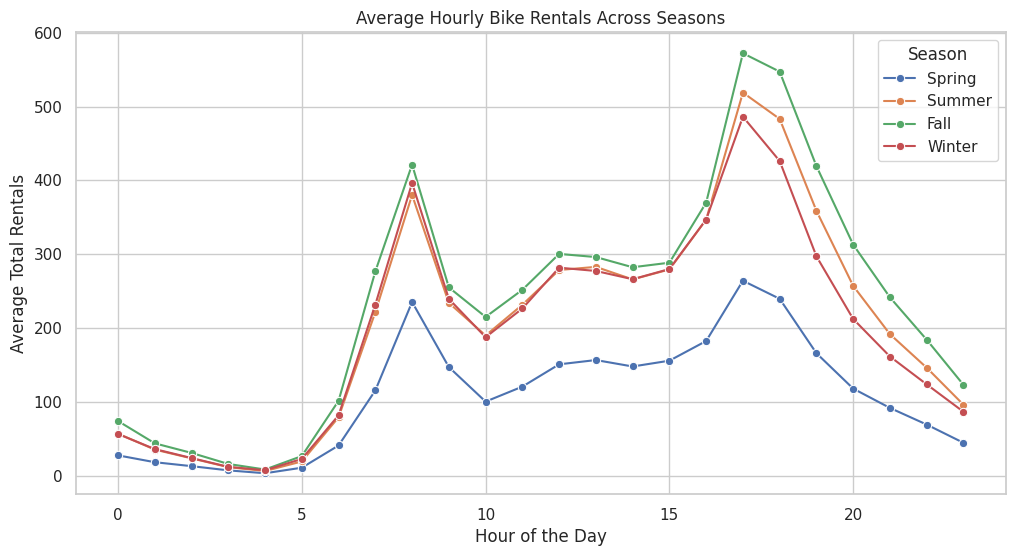

In [ ]:
sns.set_theme(style="whitegrid")

#Hourly Rental Trends by Season

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=df,
    x="Hour",
    y="Total_Rentals",
    hue="Season",
    marker="o",
    errorbar=None,
)

plt.title("Average Hourly Bike Rentals Across Seasons")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Total Rentals")
plt.legend(title="Season")
plt.show()

/tmp/ipykernel_1296/3839617962.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Weather", y="Total_Rentals", palette="Set2")


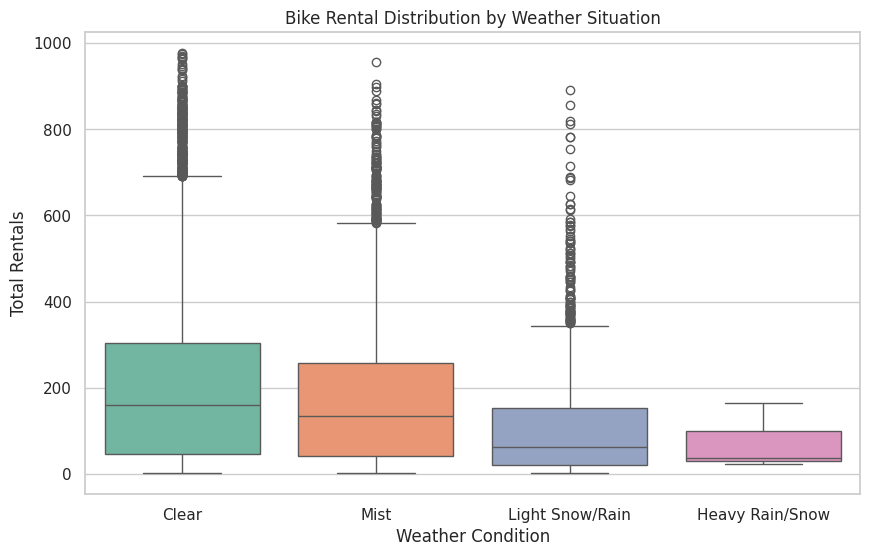

In [ ]:
#Rental Distribution by Weather Condition

plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="Weather", y="Total_Rentals", palette="Set2")
plt.title("Bike Rental Distribution by Weather Situation")
plt.xlabel("Weather Condition")
plt.ylabel("Total Rentals")
plt.show()



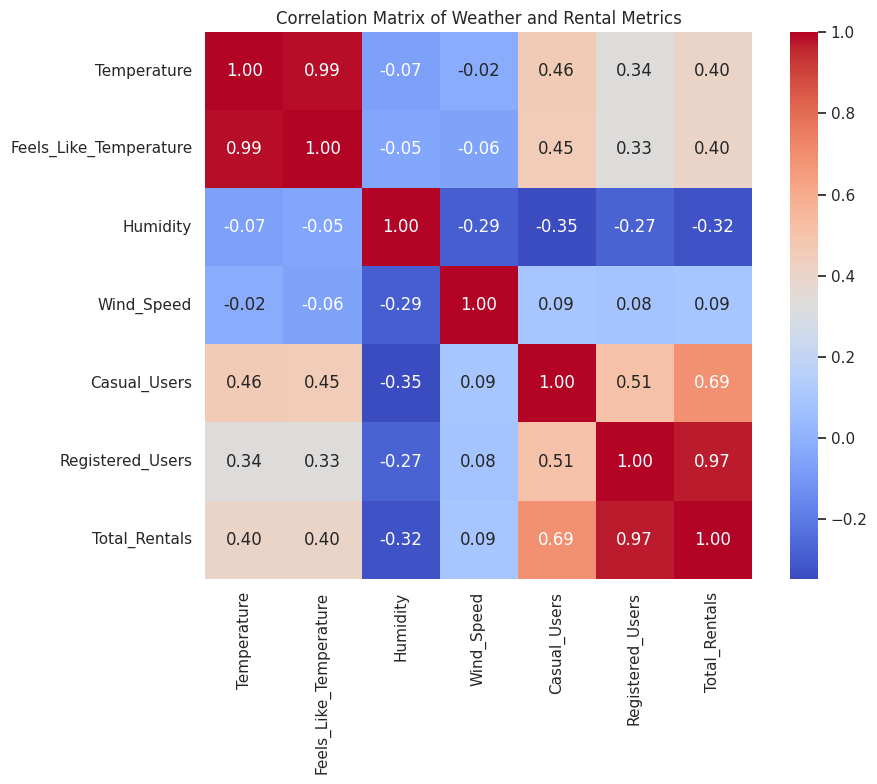

In [ ]:
#Correlation Heatmap for Numerical Features
plt.figure(figsize=(10, 8))
numerical_cols = [
      "Temperature",
      "Feels_Like_Temperature",
      "Humidity",
      "Wind_Speed",
      "Casual_Users",
      "Registered_Users",
      "Total_Rentals",
  ]

correlation_matrix = df[numerical_cols].corr()
sns.heatmap(
    correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", square=True
    )

plt.title("Correlation Matrix of Weather and Rental Metrics")
plt.tight_layout()
plt.show()





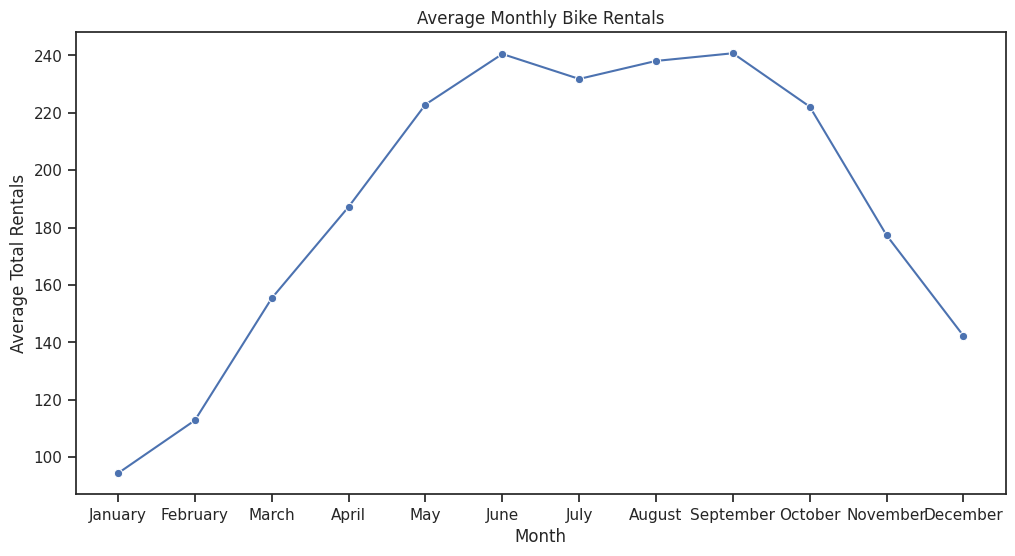

In [ ]:
sns.set_theme(style="ticks")

#Monthly Rental Trends

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=df,
    x="Month",
    y="Total_Rentals",
    marker="o",
    errorbar=None,
    sort=False,
)

plt.title("Average Monthly Bike Rentals")
plt.xlabel("Month")
plt.ylabel("Average Total Rentals")
plt.tight_layout
plt.show()

In [ ]:
df = pd.read_csv('/content/output/cleaned_bike_data.csv')
df

,Record_ID,Date,Month,Year,Hour,Season,Holiday,Weekday,Weather,Temperature,Feels_Like_Temperature,Humidity,Wind_Speed,Casual_Users,Registered_Users,Total_Rentals
0,1,2011-01-01,January,2011,0,Spring,No,Saturday,Clear,0.24,0.2879,0.81,0.0000,3,13,16
1,2,2011-01-01,January,2011,1,Spring,No,Saturday,Clear,0.22,0.2727,0.80,0.0000,8,32,40
2,3,2011-01-01,January,2011,2,Spring,No,Saturday,Clear,0.22,0.2727,0.80,0.0000,5,27,32
3,4,2011-01-01,January,2011,3,Spring,No,Saturday,Clear,0.24,0.2879,0.75,0.0000,3,10,13
4,5,2011-01-01,January,2011,4,Spring,No,Saturday,Clear,0.24,0.2879,0.75,0.0000,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17374,17375,2012-12-31,December,2012,19,Spring,No,Monday,Mist,0.26,0.2576,0.60,0.1642,11,108,119
17375,17376,2012-12-31,December,2012,20,Spring,No,Monday,Mist,0.26,0.2576,0.60,0.1642,8,81,89
17376,17377,2012-12-31,December,2012,21,Spring,No,Monday,Clear,0.26,0.2576,0.60,0.1642,7,83,90
17377,17378,2012-12-31,December,2012,22,Spring,No,Monday,Clear,0.26,0.2727,0.56,0.1343,13,48,61


In [ ]:
df.isnull().sum()

,0
Record_ID,0
Date,0
Month,0
Year,0
Hour,0
Season,0
Holiday,0
Weekday,0
Weather,0
Temperature,0


In [ ]:
df.dtypes

,0
Record_ID,int64
Date,object
Month,object
Year,int64
Hour,int64
Season,object
Holiday,object
Weekday,object
Weather,object
Temperature,float64


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.drop(columns = ['Feels_Like_Temperature'],inplace=True)
df.head()

,Record_ID,Date,Month,Year,Hour,Season,Holiday,Weekday,Weather,Temperature,Humidity,Wind_Speed,Casual_Users,Registered_Users,Total_Rentals
0,1,2011-01-01,January,2011,0,Spring,No,Saturday,Clear,0.24,0.81,0.0,3,13,16
1,2,2011-01-01,January,2011,1,Spring,No,Saturday,Clear,0.22,0.80,0.0,8,32,40
2,3,2011-01-01,January,2011,2,Spring,No,Saturday,Clear,0.22,0.80,0.0,5,27,32
3,4,2011-01-01,January,2011,3,Spring,No,Saturday,Clear,0.24,0.75,0.0,3,10,13
4,5,2011-01-01,January,2011,4,Spring,No,Saturday,Clear,0.24,0.75,0.0,0,1,1


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt


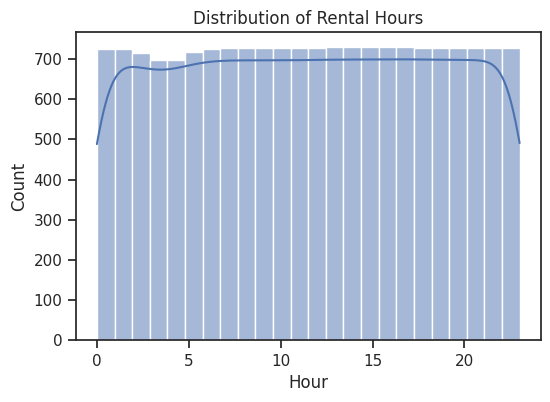

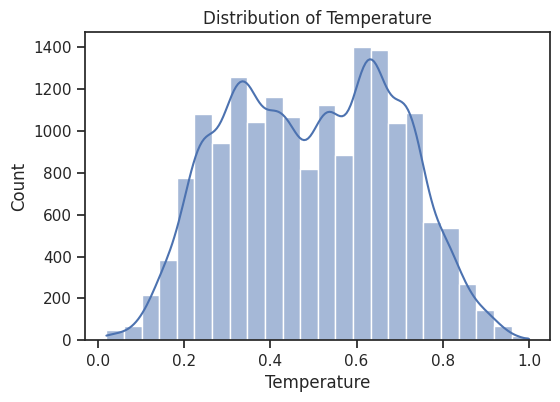

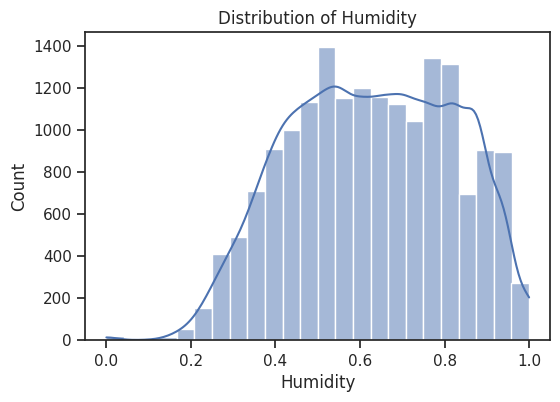

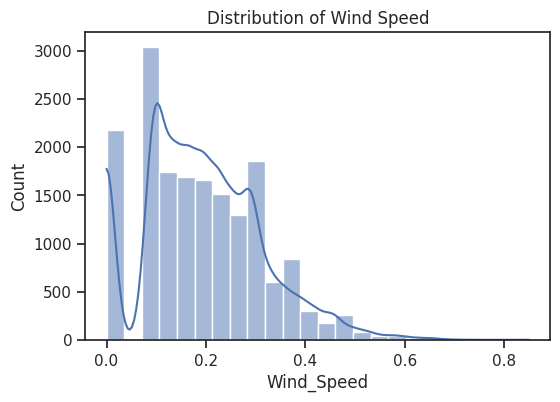

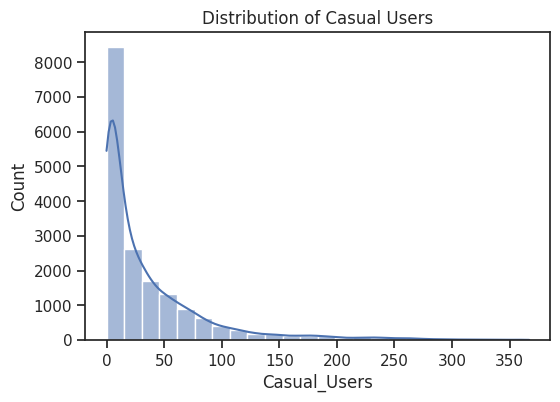

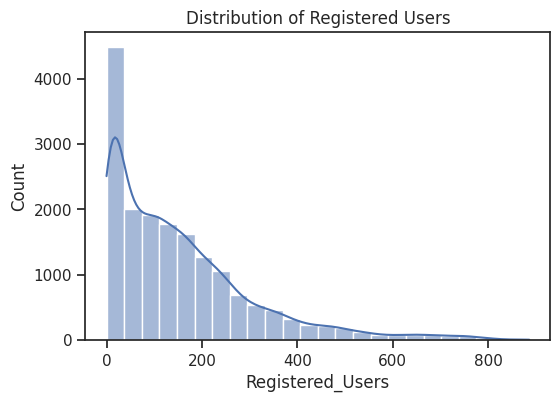

In [ ]:
#hour histogram

plt.figure(figsize=(6,4))
sns.histplot(df["Hour"], bins=24, kde=True)
plt.title("Distribution of Rental Hours")
plt.show()

#Temperature Histogram

plt.figure(figsize=(6,4))
sns.histplot(df["Temperature"], bins=24, kde=True)
plt.title("Distribution of Temperature")
plt.show()

#Humidity Histogram

plt.figure(figsize=(6,4))
sns.histplot(df["Humidity"], bins=24, kde=True)
plt.title("Distribution of Humidity")
plt.show()

#Wind_Speed Histogram

plt.figure(figsize=(6,4))
sns.histplot(df["Wind_Speed"], bins=24, kde=True)
plt.title("Distribution of Wind Speed")
plt.show()

#Casual_Users

plt.figure(figsize=(6,4))
sns.histplot(df["Casual_Users"], bins=24, kde=True)
plt.title("Distribution of Casual Users")
plt.show()

#Registered_Users

plt.figure(figsize=(6,4))
sns.histplot(df["Registered_Users"], bins=24, kde=True)
plt.title("Distribution of Registered Users")
plt.show()








In [ ]:
columns = ["Hour","Temperature", "Humidity", "Wind_Speed", "Casual_Users", "Registered_Users"]

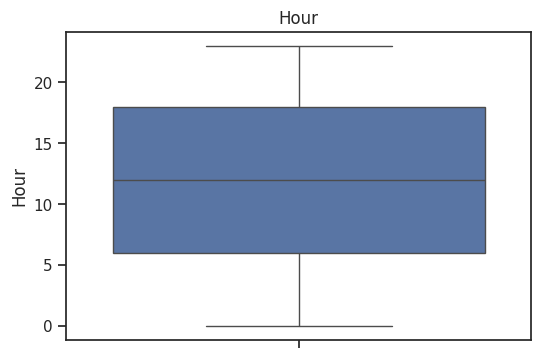

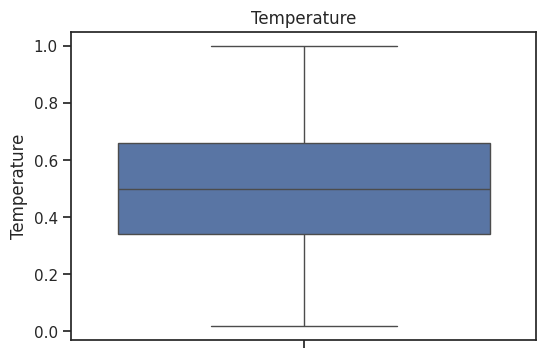

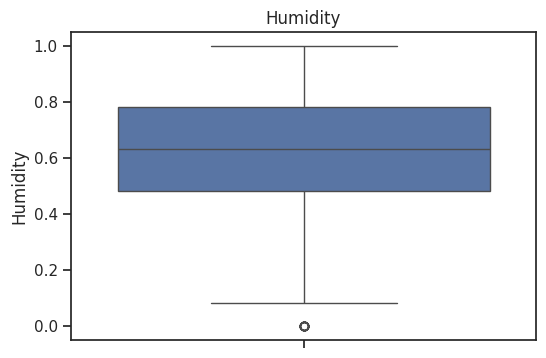

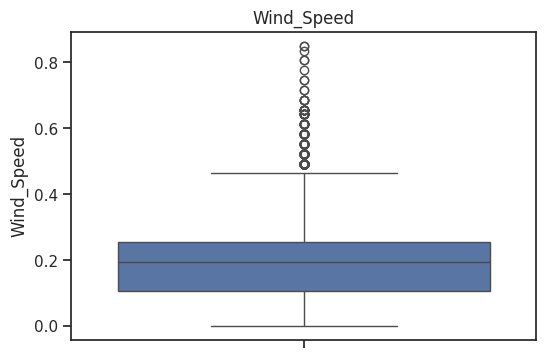

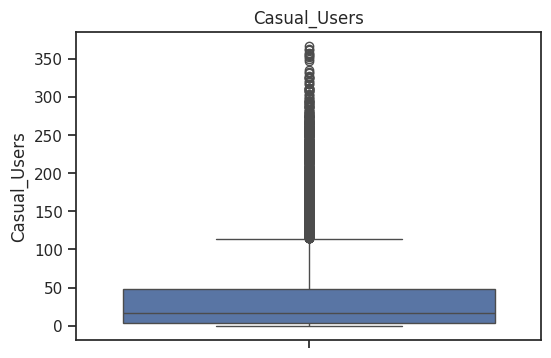

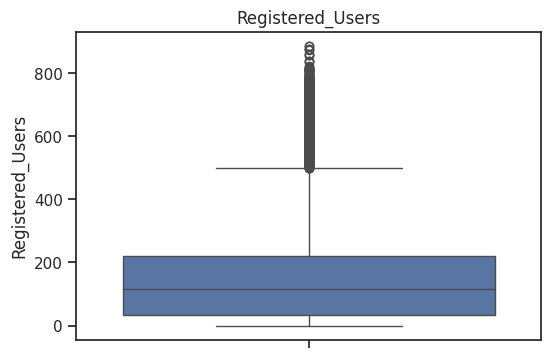

In [ ]:
for i in columns:
  plt.figure(figsize=(6,4))
  sns.boxplot(df[i])
  plt.title(i)
  plt.show()


In [ ]:
from scipy.stats.mstats import winsorize

winsor_cols = [
    "Wind_Speed",
    "Casual_Users",
    "Registered_Users",
]

for col in winsor_cols:
    df[col] = winsorize(df[col], limits=[0.02, 0.02])

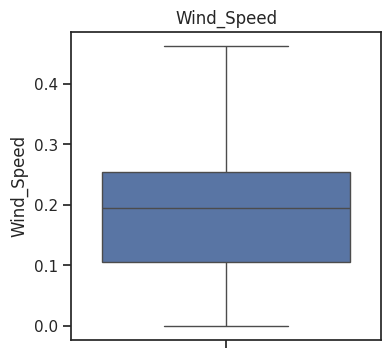

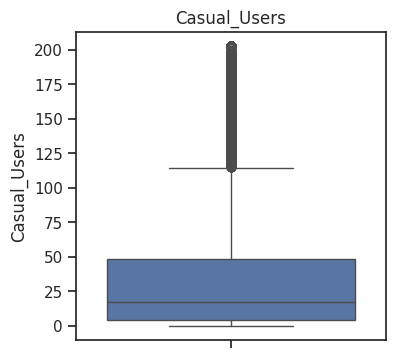

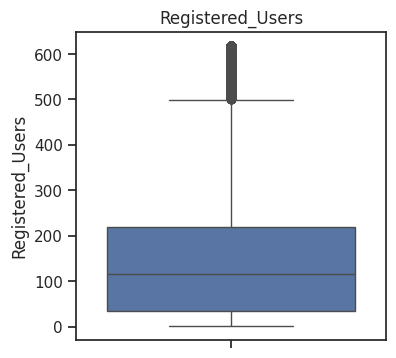

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

for col in winsor_cols:
    plt.figure(figsize=(4,4))
    sns.boxplot(y=df[col])
    plt.title(col)
    plt.show()

In [ ]:
df['Casual_Users'].skew()

np.float64(2.0049738349444572)

In [ ]:
df.head()

,Record_ID,Date,Month,Year,Hour,Season,Holiday,Weekday,Weather,Temperature,Humidity,Wind_Speed,Casual_Users,Registered_Users,Total_Rentals
0,1,2011-01-01,January,2011,0,Spring,No,Saturday,Clear,0.24,0.81,0.0,3,13,16
1,2,2011-01-01,January,2011,1,Spring,No,Saturday,Clear,0.22,0.80,0.0,8,32,40
2,3,2011-01-01,January,2011,2,Spring,No,Saturday,Clear,0.22,0.80,0.0,5,27,32
3,4,2011-01-01,January,2011,3,Spring,No,Saturday,Clear,0.24,0.75,0.0,3,10,13
4,5,2011-01-01,January,2011,4,Spring,No,Saturday,Clear,0.24,0.75,0.0,0,2,1


**Encoding**

In [ ]:
df.drop(columns = ['Date'],inplace=True)
df.head()

,Record_ID,Month,Year,Hour,Season,Holiday,Weekday,Weather,Temperature,Humidity,Wind_Speed,Casual_Users,Registered_Users,Total_Rentals
0,1,January,2011,0,Spring,No,Saturday,Clear,0.24,0.81,0.0,3,13,16
1,2,January,2011,1,Spring,No,Saturday,Clear,0.22,0.80,0.0,8,32,40
2,3,January,2011,2,Spring,No,Saturday,Clear,0.22,0.80,0.0,5,27,32
3,4,January,2011,3,Spring,No,Saturday,Clear,0.24,0.75,0.0,3,10,13
4,5,January,2011,4,Spring,No,Saturday,Clear,0.24,0.75,0.0,0,2,1


In [ ]:
df['Season'].value_counts()

,count
Season,
Fall,4496
Summer,4409
Spring,4242
Winter,4232


In [ ]:
from sklearn.preprocessing import LabelEncoder

In [ ]:
label = LabelEncoder()
df["Season"] = label.fit_transform(df["Season"])
df.head()

,Record_ID,Month,Year,Hour,Season,Holiday,Weekday,Weather,Temperature,Humidity,Wind_Speed,Casual_Users,Registered_Users,Total_Rentals
0,1,January,2011,0,1,No,Saturday,Clear,0.24,0.81,0.0,3,13,16
1,2,January,2011,1,1,No,Saturday,Clear,0.22,0.80,0.0,8,32,40
2,3,January,2011,2,1,No,Saturday,Clear,0.22,0.80,0.0,5,27,32
3,4,January,2011,3,1,No,Saturday,Clear,0.24,0.75,0.0,3,10,13
4,5,January,2011,4,1,No,Saturday,Clear,0.24,0.75,0.0,0,2,1


In [ ]:
from sklearn.preprocessing import LabelEncoder

le_month = LabelEncoder()

df["Month"] = le_month.fit_transform(df["Month"])

In [ ]:
label = LabelEncoder()
df["Holiday"] = label.fit_transform(df["Season"])
df.head()

,Record_ID,Month,Year,Hour,Season,Holiday,Weekday,Weather,Temperature,Humidity,Wind_Speed,Casual_Users,Registered_Users,Total_Rentals
0,1,4,2011,0,1,1,Saturday,Clear,0.24,0.81,0.0,3,13,16
1,2,4,2011,1,1,1,Saturday,Clear,0.22,0.80,0.0,8,32,40
2,3,4,2011,2,1,1,Saturday,Clear,0.22,0.80,0.0,5,27,32
3,4,4,2011,3,1,1,Saturday,Clear,0.24,0.75,0.0,3,10,13
4,5,4,2011,4,1,1,Saturday,Clear,0.24,0.75,0.0,0,2,1


In [ ]:
df['Weekday'] = df['Weekday'].map({
    "Sunday": 0,
    "Monday": 1,
    "Tuesday": 2,
    "Wednesday": 3,
    "Thursday": 4,
    "Friday": 5,
    "Saturday": 6
})
df.head()

,Record_ID,Month,Year,Hour,Season,Holiday,Weekday,Weather,Temperature,Humidity,Wind_Speed,Casual_Users,Registered_Users,Total_Rentals
0,1,4,2011,0,1,1,6,Clear,0.24,0.81,0.0,3,13,16
1,2,4,2011,1,1,1,6,Clear,0.22,0.80,0.0,8,32,40
2,3,4,2011,2,1,1,6,Clear,0.22,0.80,0.0,5,27,32
3,4,4,2011,3,1,1,6,Clear,0.24,0.75,0.0,3,10,13
4,5,4,2011,4,1,1,6,Clear,0.24,0.75,0.0,0,2,1


In [ ]:
df['Weekday'].value_counts()

,count
Weekday,
6,2512
0,2502
5,2487
1,2479
3,2475
4,2471
2,2453


In [ ]:
df['Weather'] = df['Weather'].map({
    "Clear": 1,
    "Mist": 2,
    "Light Snow/Rain": 3,
    "Heavy Rain/Snow": 4
})
df.head()

,Record_ID,Month,Year,Hour,Season,Holiday,Weekday,Weather,Temperature,Humidity,Wind_Speed,Casual_Users,Registered_Users,Total_Rentals
0,1,4,2011,0,1,1,6,1,0.24,0.81,0.0,3,13,16
1,2,4,2011,1,1,1,6,1,0.22,0.80,0.0,8,32,40
2,3,4,2011,2,1,1,6,1,0.22,0.80,0.0,5,27,32
3,4,4,2011,3,1,1,6,1,0.24,0.75,0.0,3,10,13
4,5,4,2011,4,1,1,6,1,0.24,0.75,0.0,0,2,1


**Split**

In [ ]:
X = df.drop(columns=["Total_Rentals","Casual_Users","Registered_Users","Record_ID"], axis=1)
y = df["Total_Rentals"]

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (13903, 10)
X_test : (3476, 10)
y_train: (13903,)
y_test : (3476,)


In [ ]:
y_train.value_counts()


,count
Total_Rentals,
5,207
4,187
6,183
3,169
2,166
...,...
689,1
795,1
793,1


In [ ]:
X_train.dtypes

,0
Month,int64
Year,int64
Hour,int64
Season,int64
Holiday,int64
Weekday,int64
Weather,int64
Temperature,float64
Humidity,float64
Wind_Speed,float64


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Record_ID         17379 non-null  int64  
 1   Month             17379 non-null  int64  
 2   Year              17379 non-null  int64  
 3   Hour              17379 non-null  int64  
 4   Season            17379 non-null  int64  
 5   Holiday           17379 non-null  int64  
 6   Weekday           17379 non-null  int64  
 7   Weather           17379 non-null  int64  
 8   Temperature       17379 non-null  float64
 9   Humidity          17379 non-null  float64
 10  Wind_Speed        17379 non-null  float64
 11  Casual_Users      17379 non-null  int64  
 12  Registered_Users  17379 non-null  int64  
 13  Total_Rentals     17379 non-null  int64  
dtypes: float64(3), int64(11)
memory usage: 1.9 MB


In [ ]:
X_train.dtypes

,0
Month,int64
Year,int64
Hour,int64
Season,int64
Holiday,int64
Weekday,int64
Weather,int64
Temperature,float64
Humidity,float64
Wind_Speed,float64


**Scaling**

In [ ]:
from sklearn.preprocessing import RobustScaler
scaler = RobustScaler()

In [ ]:
scale_cols = [
    "Temperature",
    "Humidity",
    "Wind_Speed",

]
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test[scale_cols] = scaler.transform(X_test[scale_cols])



In [ ]:
X_train.head()

,Month,Year,Hour,Season,Holiday,Weekday,Weather,Temperature,Humidity,Wind_Speed
335,4,2011,11,1,1,6,1,-0.9375,-0.258065,0.400134
7035,10,2011,18,3,3,2,1,0.0625,-0.677419,-0.400134
8051,2,2011,3,3,3,3,3,-0.1250,1.193548,0.400134
2133,0,2011,18,2,2,0,2,-0.1250,-1.032258,-1.100536
8485,2,2011,6,1,1,0,1,-0.9375,0.387097,-0.400134


In [ ]:
X_train.describe()

,Month,Year,Hour,Season,Holiday,Weekday,Weather,Temperature,Humidity,Wind_Speed
count,13903.000000,13903.000000,13903.000000,13903.000000,13903.000000,13903.000000,13903.000000,13903.000000,13903.000000,13903.000000
mean,5.507588,2011.502050,11.557146,1.483996,1.483996,2.998202,1.426023,-0.008137,-0.009641,0.160631
std,3.452047,0.500014,6.911927,1.122871,1.122871,2.011350,0.638842,0.603177,0.621939,0.788044
min,0.000000,2011.000000,0.000000,0.000000,0.000000,0.000000,1.000000,-1.500000,-2.032258,-1.100536
25%,2.000000,2011.000000,6.000000,0.000000,0.000000,1.000000,1.000000,-0.500000,-0.516129,-0.400134
50%,6.000000,2012.000000,12.000000,1.000000,1.000000,3.000000,1.000000,0.000000,0.000000,0.000000
75%,8.000000,2012.000000,18.000000,2.000000,2.000000,5.000000,2.000000,0.500000,0.483871,0.599866
max,11.000000,2012.000000,23.000000,3.000000,3.000000,6.000000,4.000000,1.562500,1.193548,2.000670


In [ ]:
corr = df.corr(numeric_only=True)
corr

,Record_ID,Month,Year,Hour,Season,Holiday,Weekday,Weather,Temperature,Humidity,Wind_Speed,Casual_Users,Registered_Users,Total_Rentals
Record_ID,1.000000,0.137973,0.866014,-0.004775,0.155249,0.155249,0.001357,-0.014198,0.136178,0.009577,-0.074012,0.156438,0.280798,0.278379
Month,0.137973,1.000000,-0.006157,-0.001283,0.282741,0.282741,0.001168,0.024278,0.106548,0.134537,-0.074848,0.082314,0.083319,0.093074
Year,0.866014,-0.006157,1.000000,-0.003867,-0.006572,-0.006572,-0.004485,-0.019157,0.040913,-0.083546,-0.009274,0.137508,0.252577,0.250495
Hour,-0.004775,-0.001283,-0.003867,1.000000,-0.001354,-0.001354,-0.003498,-0.020203,0.137603,-0.276498,0.138041,0.319703,0.384328,0.394071
Season,0.155249,0.282741,-0.006572,-0.001354,1.000000,1.000000,-0.009910,0.072684,-0.361958,0.082580,-0.006472,-0.075031,0.006579,-0.013157
Holiday,0.155249,0.282741,-0.006572,-0.001354,1.000000,1.000000,-0.009910,0.072684,-0.361958,0.082580,-0.006472,-0.075031,0.006579,-0.013157
Weekday,0.001357,0.001168,-0.004485,-0.003498,-0.009910,-0.009910,1.000000,0.003311,-0.001795,-0.037158,0.010417,0.025605,0.023360,0.026900
Weather,-0.014198,0.024278,-0.019157,-0.020203,0.072684,0.072684,0.003311,1.000000,-0.102640,0.418130,0.024794,-0.157917,-0.122787,-0.142426
Temperature,0.136178,0.106548,0.040913,0.137603,-0.361958,-0.361958,-0.001795,-0.102640,1.000000,-0.069881,-0.019610,0.483709,0.340091,0.404772
Humidity,0.009577,0.134537,-0.083546,-0.276498,0.082580,0.082580,-0.037158,0.418130,-0.069881,1.000000,-0.290471,-0.357734,-0.280484,-0.322911


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Record_ID         17379 non-null  int64  
 1   Month             17379 non-null  int64  
 2   Year              17379 non-null  int64  
 3   Hour              17379 non-null  int64  
 4   Season            17379 non-null  int64  
 5   Holiday           17379 non-null  int64  
 6   Weekday           17379 non-null  int64  
 7   Weather           17379 non-null  int64  
 8   Temperature       17379 non-null  float64
 9   Humidity          17379 non-null  float64
 10  Wind_Speed        17379 non-null  float64
 11  Casual_Users      17379 non-null  int64  
 12  Registered_Users  17379 non-null  int64  
 13  Total_Rentals     17379 non-null  int64  
dtypes: float64(3), int64(11)
memory usage: 1.9 MB


In [ ]:
df.head()

,Record_ID,Month,Year,Hour,Season,Holiday,Weekday,Weather,Temperature,Humidity,Wind_Speed,Casual_Users,Registered_Users,Total_Rentals
0,1,4,2011,0,1,1,6,1,0.24,0.81,0.0,3,13,16
1,2,4,2011,1,1,1,6,1,0.22,0.80,0.0,8,32,40
2,3,4,2011,2,1,1,6,1,0.22,0.80,0.0,5,27,32
3,4,4,2011,3,1,1,6,1,0.24,0.75,0.0,3,10,13
4,5,4,2011,4,1,1,6,1,0.24,0.75,0.0,0,2,1


In [ ]:
df['Month'].value_counts()

,count
Month,
5,1488
8,1488
2,1483
1,1475
7,1473
10,1451
6,1440
0,1437
11,1437


In [ ]:
df['Month'].unique()

array([ 4,  3,  7,  0,  8,  6,  5,  1, 11, 10,  9,  2])

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
from sklearn.linear_model import Lasso


In [ ]:
lr_model = LinearRegression()

lr_model.fit(X_train,y_train)


LinearRegression()

In [ ]:
y_pred = lr_model.predict(X_test)

In [ ]:
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
mse = mean_squared_error(y_test,y_pred)
mae = mean_absolute_error(y_test,y_pred)
r2 = r2_score(y_test,y_pred)
print(f"MSE: {mse}")
print(f"MAE: {mae}")
print(f"R2: {r2}")

MSE: 19093.05563805761
MAE: 103.76881716668673
R2: 0.3970374982599525


In [ ]:
dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train, y_train)

DecisionTreeRegressor(random_state=42)

In [ ]:
y_pred = dt_model.predict(X_test)

In [ ]:
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
mse = mean_squared_error(y_test,y_pred)
mae = mean_absolute_error(y_test,y_pred)
r2 = r2_score(y_test,y_pred)
print(f"MSE: {mse}")
print(f"MAE: {mae}")
print(f"R2: {r2}")

MSE: 4637.110184119678
MAE: 38.29430379746835
R2: 0.8535591363444275


In [ ]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [ ]:
y_pred_rf = rf_model.predict(X_test)

In [ ]:
mse_rf = mean_squared_error(y_test, y_pred_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print(f"MSE: {mse_rf}")
print(f"MAE: {mae_rf}")
print(f"R2: {r2_rf}")

MSE: 2394.6830408601404
MAE: 28.2995557633295
R2: 0.9243754323790161


In [ ]:
#Initialize the three models
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
}

# 5. Train and compare performance
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MSE": round(mse, 2),
        "MAE": round(mae, 2),
        "R2 Score": round(r2, 4)
    })

# Display comparative results table
comparison_df = pd.DataFrame(results)
print(comparison_df.to_string(index=False))

            Model      MSE    MAE  R2 Score
Linear Regression 19093.06 103.77    0.3970
    Decision Tree  4637.11  38.29    0.8536
    Random Forest  2394.68  28.30    0.9244


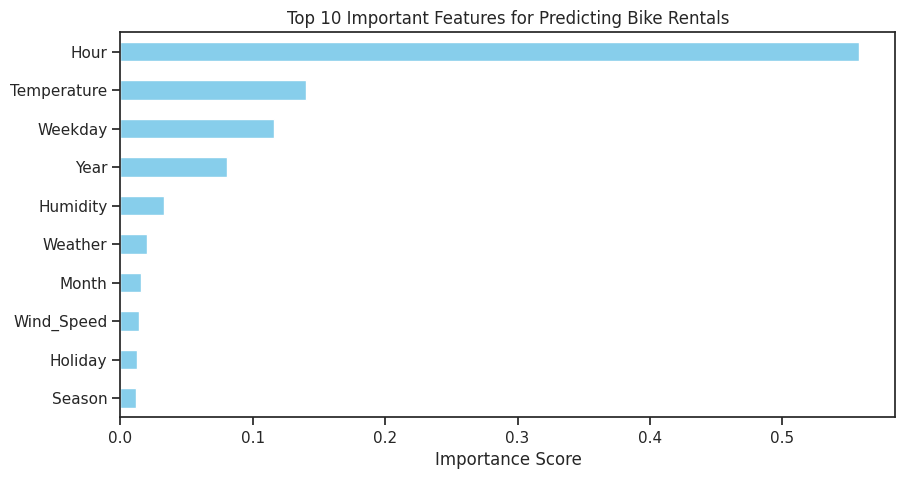

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Get feature importances
importances = pd.Series(rf_model.feature_importances_, index=X_train.columns)
top_10 = importances.nlargest(10)

# Plot top 10 features
plt.figure(figsize=(10, 5))
top_10.plot(kind='barh', color='skyblue')
plt.title("Top 10 Important Features for Predicting Bike Rentals")
plt.xlabel("Importance Score")
plt.gca().invert_yaxis()
plt.show()

In [ ]:
# Create a comparison DataFrame for the first 100 test samples
comparison_df = pd.DataFrame({
    'Actual': y_test.values[:100],
    'Predicted': y_pred_rf[:100]
}).reset_index(drop=True)
comparison_df.head(10)

,Actual,Predicted
0,425,385.07
1,88,143.17
2,4,13.24
3,526,531.14
4,13,14.24
5,32,44.17
6,706,725.34
7,26,44.62
8,2,9.75
9,21,26.40


In [ ]:
lasso_model = Lasso(alpha=1.0, random_state=42)

# 2. Fit/Train the model
lasso_model.fit(X_train, y_train)

# 3. Make predictions
y_pred = lasso_model.predict(X_test)

# 4. Evaluate performance
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MSE : {mse:.4f}")
print(f"MAE : {mae:.4f}")
print(f"R²  : {r2:.4f}")

MSE : 19093.4719
MAE : 103.5168
R²  : 0.3970


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, r2_score

# 1. Base Regressor
rf_reg = RandomForestRegressor(random_state=0)

# 2. Parameter Grid
param_dist = {
    'n_estimators': [50, 100],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5]
}

# 3. RandomizedSearchCV for Regression
random_search_reg = RandomizedSearchCV(
    estimator=rf_reg,
    param_distributions=param_dist,
    n_iter=4,
    cv=3,
    scoring='r2',  # Evaluates R-squared variance explained
    n_jobs=1,
    random_state=0
)

# 4. Fit Model
random_search_reg.fit(X_train, y_train)

# 5. Best Regressor Evaluation
best_reg = random_search_reg.best_estimator_
y_pred = best_reg.predict(X_test)

print("Best Parameters:", random_search_reg.best_params_)
print("Test R2 Score:", r2_score(y_test, y_pred))
print("Test MAE:", mean_absolute_error(y_test, y_pred))

Best Parameters: {'n_estimators': 100, 'min_samples_split': 5, 'max_depth': None}
Test R2 Score: 0.926199106704022
Test MAE: 28.21841735333216


/tmp/ipykernel_1296/2428101039.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values, y=importances.index, palette="viridis")


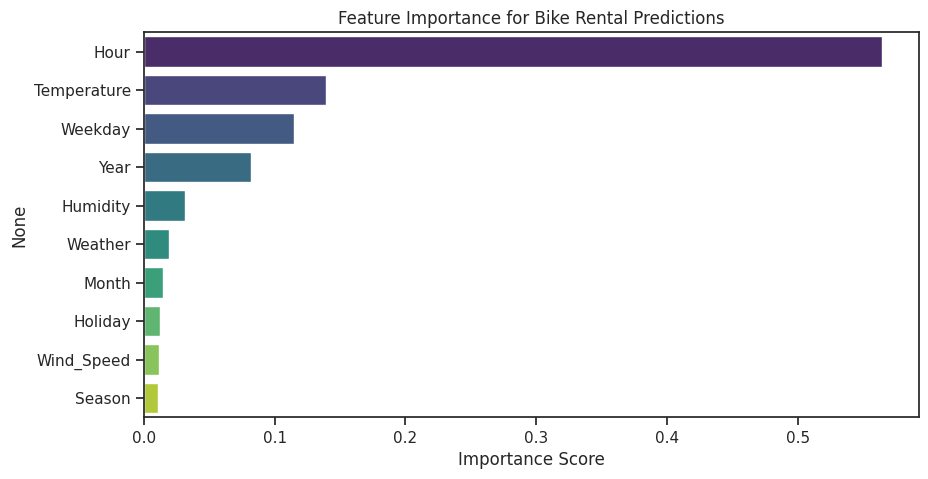

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

importances = pd.Series(best_reg.feature_importances_, index=X_train.columns)
importances = importances.sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=importances.values, y=importances.index, palette="viridis")
plt.title("Feature Importance for Bike Rental Predictions")
plt.xlabel("Importance Score")
plt.show()

In [ ]:
# 1. Create comparison DataFrame for the first 100 test samples
comparison_df = pd.DataFrame({
    'Actual': y_test.values[:100],
    'Predicted': y_pred_rf[:100],
    'Difference (Error)': y_test.values[:100] - y_pred_rf[:100]
}).reset_index(drop=True)

# 2. Display the top 10 rows
display(comparison_df.head(10))

,Actual,Predicted,Difference (Error)
0,425,385.07,39.93
1,88,143.17,-55.17
2,4,13.24,-9.24
3,526,531.14,-5.14
4,13,14.24,-1.24
5,32,44.17,-12.17
6,706,725.34,-19.34
7,26,44.62,-18.62
8,2,9.75,-7.75
9,21,26.40,-5.40


In [ ]:
!pip install xgboost

In [ ]:
import numpy as np
import pandas as pd
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# 1. Initialize XGBoost Regressor
xgb = XGBRegressor(random_state=0, objective='reg:squarederror')

# 2. Define XGBoost hyperparameter search space
param_dist_xgb = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [3, 6, 10],
    'subsample': [0.7, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0],
    'min_child_weight': [1, 3, 5]
}

# 3. Setup RandomizedSearchCV
random_search_xgb = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_dist_xgb,
    n_iter=10,             # Number of random combinations to try
    cv=3,                  # 3-fold Cross Validation
    scoring='r2',
    n_jobs=1,              # Set to 1 to avoid Colab RAM OOM crashes
    random_state=0,
    verbose=1
)

# 4. Fit on Training Data
random_search_xgb.fit(X_train, y_train)

# 5. Evaluate on Test Data
best_xgb = random_search_xgb.best_estimator_
y_pred_xgb = best_xgb.predict(X_test)

# Metrics
r2 = r2_score(y_test, y_pred_xgb)
mae = mean_absolute_error(y_test, y_pred_xgb)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb))

print("=== XGBoost Results ===")
print("Best Parameters:", random_search_xgb.best_params_)
print(f"Test R² Score: {r2:.4f}")
print(f"Test MAE: {mae:.2f}")
print(f"Test RMSE: {rmse:.2f}")

Fitting 3 folds for each of 10 candidates, totalling 30 fits
=== XGBoost Results ===
Best Parameters: {'subsample': 1.0, 'n_estimators': 300, 'min_child_weight': 3, 'max_depth': 6, 'learning_rate': 0.2, 'colsample_bytree': 1.0}
Test R² Score: 0.9380
Test MAE: 27.00
Test RMSE: 44.31


In [ ]:
# 1. Create comparison DataFrame for the first 100 test samples
comparison_df = pd.DataFrame({
    'Actual': y_test.values[:100],
    'Predicted': y_pred_xgb[:100],
    'Difference (Error)': y_test.values[:100] - y_pred_xgb[:100]
}).reset_index(drop=True)

# 2. Display the top 10 rows
display(comparison_df.head(10))

,Actual,Predicted,Difference (Error)
0,425,395.228088,29.771912
1,88,147.636581,-59.636581
2,4,19.457552,-15.457552
3,526,476.505707,49.494293
4,13,24.174425,-11.174425
5,32,29.018269,2.981731
6,706,735.162781,-29.162781
7,26,54.850285,-28.850285
8,2,2.582263,-0.582263
9,21,31.884712,-10.884712


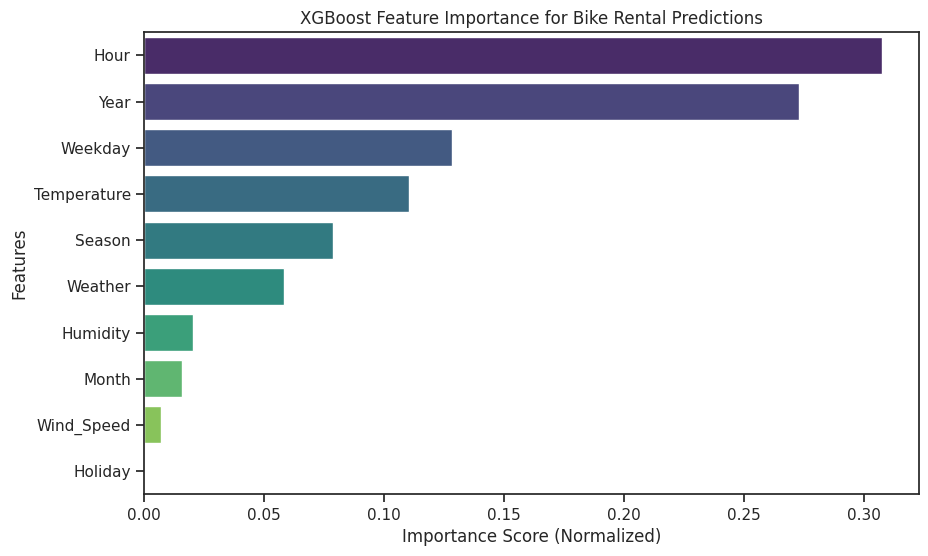

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Access feature importances from the best XGBoost estimator
importances_xgb = pd.Series(best_xgb.feature_importances_, index=X_train.columns)

# 2. Sort them in descending order
importances_xgb = importances_xgb.sort_values(ascending=False)

# 3. Plot using Seaborn barplot
plt.figure(figsize=(10, 6))
sns.barplot(x=importances_xgb.values, y=importances_xgb.index, palette="viridis", hue=importances_xgb.index, legend=False)

# 4. Add titles and labels
plt.title("XGBoost Feature Importance for Bike Rental Predictions")
plt.xlabel("Importance Score (Normalized)")
plt.ylabel("Features")
plt.show()

In [ ]:
final_model = best_xgb

In [ ]:
best_xgb.save_model("model.json")

In [ ]:
import numpy as np
import pandas as pd

new_data = pd.DataFrame({
    "Month": [7],
    "Year": [2012],
    "Hour": [18],
    "Season": [2],
    "Holiday": [0],
    "Weekday": [5],
    "Weather": [0],
    "Temperature": [0.70],
    "Humidity": [0.50],
    "Wind_Speed": [0.20]
})

# Cyclic features
new_data["Hour_sin"] = np.sin(2 * np.pi * new_data["Hour"] / 24)
new_data["Hour_cos"] = np.cos(2 * np.pi * new_data["Hour"] / 24)

new_data["Month_sin"] = np.sin(2 * np.pi * new_data["Month"] / 12)
new_data["Month_cos"] = np.cos(2 * np.pi * new_data["Month"] / 12)

# Make sure columns are in the same order as training data
new_data = new_data[X_train.columns]

# Prediction using FINAL XGBoost model
prediction = final_model.predict(new_data)

print("Predicted Bike Rentals:", round(prediction[0], 2))

Predicted Bike Rentals: 626.38


In [ ]:
import pickle
import numpy as np
import pandas as pd
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, LabelEncoder
from google.colab import files

# 1. Define Features based on your cleaned dataset columns
cat_features = ['Month', 'Year', 'Season', 'Holiday', 'Weekday', 'Weather']
num_features = ['Hour', 'Temperature', 'Humidity', 'Wind_Speed']
target = 'Total_Rentals'

# Create feature matrix X and target vector y
X = df[cat_features + num_features].copy()
y = df[target].copy()

# Split into Train and Test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Fit LabelEncoder for EACH categorical feature
label_encoders = {}
for col in cat_features:
    le = LabelEncoder()
    X_train[col] = le.fit_transform(X_train[col].astype(str))
    X_test[col] = le.transform(X_test[col].astype(str))
    label_encoders[col] = le  # Store fitted encoder dictionary

# 3. Fit RobustScaler on Numerical Features
scaler = RobustScaler()
X_train[num_features] = scaler.fit_transform(X_train[num_features])
X_test[num_features] = scaler.transform(X_test[num_features])

# 4. Train XGBoost Model
model = XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=6, random_state=42)
model.fit(X_train, y_train)

# 5. Save Model, LabelEncoders, and RobustScaler as separate .pickle files
with open("model.pickle", "wb") as f:
    pickle.dump(model, f)

with open("encoder.pickle", "wb") as f:
    pickle.dump(label_encoders, f)

with open("scaler.pickle", "wb") as f:
    pickle.dump(scaler, f)

print("✅ model.pickle, encoder.pickle, and scaler.pickle saved successfully!")

# 6. Trigger automatic browser download for all 3 files
files.download("model.pickle")
files.download("encoder.pickle")
files.download("scaler.pickle")

✅ model.pickle, encoder.pickle, and scaler.pickle saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download("model.pickle")
files.download("encoder.pickle")
files.download("scaler.pickle")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import xgboost

print(xgboost.__version__)

3.4.1
